# To What Extent Do Education and Hours Worked Dominate Demographic Variables in Predicting Weekly Earnings? 
**Evidence from CPS December 2024**

## Introduction
In this project, we study the factors that determine weekly earnings using data from CPS December 2024 sample. In literature on labor economics, earnings have been found to be correlated with certain variables like education, labor supply, and some other demographic characteristics. Yet, all of these factors are not equally likely to be strong indicators of earnings. For instance, factors like education and number of hours worked are likely to have a stronger correlation with weekly earnings compared to demographic background.

This project is focused at comparing the influence of demographic variables and variables that are likely to have a direct impact on weekly earnings. Specifically, the project asks: What is the extent to which education and hours worked outweigh demographic variables in explaining weekly earnings in CPS December 2024?

To find an answer to the research question, the project proposes to employ a random forest regression. It would help us uncover more complicated relationships in the dataset as well as enable us to measure variables' contribution. Thus, we will try to see how much education and hours worked matter for the explanation of weekly earnings compared to demographic factors such as age, gender, race, marriage status, and citizenship.

Education and number of hours worked are expected to show a higher degree of influence on weekly earnings than demographic characteristics since they affect skills and productivity directly.

## Research Question and Objective
This project is dedicated to exploring the following research question:

How much do education and hours worked overshadow other demographic factors in determining weekly earnings among individuals in the CPS December 2024 sample?

The overall aim of the current project lies in using machine learning methods for assessing the importance of various variables in predicting weekly earnings. Specifically, it should be highlighted that the study compares the contribution of education and hours worked versus a number of demographic variables such as age, sex, race, marriage, and citizenship.

One may argue that the above question is quite relevant because there are several factors that determine weekly earnings, however, not all of them have equal importance. Thus, education stands for human capital, whereas hours worked stand for labor supply. Moreover, these two factors are strongly associated with weekly earnings within the context of economics. At the same time, some demographic variables may contribute to earnings as well, but less importantly.

The hypothesis of the current study suggests that education and hours worked will outweigh other demographic variables in importance for weekly earnings prediction.

## Data Description
This project uses data from the Current Population Survey (CPS), December 2024. The CPS is a large monthly survey that collects information on labor force participation, earnings, and demographic characteristics of individuals in the United States. Because the full dataset contains a very large number of variables, only a selected group of variables relevant to the research question was used for this project.

The dependent variable in the project is weekly earnings, measured using the variable PTERNWA. Since the raw dataset includes many individuals with missing or invalid earnings values, the sample was restricted to observations with valid positive earnings. The main explanatory variables were chosen to reflect the two categories being compared in the research question.

The first category includes the variables expected to play the strongest role in earnings prediction:

Education and Hours worked

The second category includes demographic variables:

Age, Sex, Race, Marital status and Citizenship

These variables were selected because they are commonly associated with labor market outcomes and provide a useful way to compare human capital and labor supply factors against demographic characteristics. Since the original CPS file is very large, the dataset was reduced to include only the variables needed for the project. This made the data easier to clean, analyze, and use in the random forest model.

## Data Cleaning and Preparation
Given the large size of the CPS December 2024 data, the initial stage of this project focus on reducing the dataset to the relevant variables only. The response variable is weekly wages, while the predictors will consist of years of education, hours of work per week, age, gender, race, marital status, and nationality.

In preparing the data, this project maintains only observations where both weekly wage and hours of work are valid and non-missing values. In addition, weekly wages are adjusted for dollars, and the logarithm of the wage is taken to address any skewness. Finally, missing values in the selected set of variables are dropped from the dataset to estimate the model.

## Variables and Parameters

**Dependent Variable**

| Variable | Meaning | Description |
|---|---|---|
| **PTERNWA** | Weekly earnings | Weekly earnings of the individual. This is the outcome variable the model aims to predict. |

**Predictor Variables**

| Variable | Meaning | Description |
|---|---|---|
| **PEEDUCA** | Education | Highest level of educational attainment. |
| **PEHRACT1** | Actual hours worked | Number of hours actually worked. |
| **PEHRUSL1** | Usual hours worked | Number of hours usually worked. |
| **PRTAGE** | Age | Age of the individual. |
| **PESEX** | Sex | Sex of the individual. |
| **PTDTRACE** | Race | Race of the individual. |
| **PEMARITL** | Marital status | Marital status of the individual. |
| **PRCITSHP** | Citizenship | Citizenship status of the individual. |

**Model Parameters**

| Parameter | Meaning | Description |
|---|---|---|
| **k** | Number of folds | Number of folds used in cross validation. |
| **n_estimators** | Number of trees | Number of decision trees in the random forest. |
| **max_depth** | Maximum tree depth | Controls how deep each tree can grow. |
| **min_samples_split** | Minimum split size | Minimum number of observations required to split a node. |
| **min_samples_leaf** | Minimum leaf size | Minimum number of observations required in a terminal node. |
| **max_features** | Features per split | Number of predictors considered at each split. |

In [35]:
import numpy as np
import pandas as pd

# Variables needed
usecols = [
    'PTERNWA',    # weekly earnings
    'PRTAGE',     # age
    'PESEX',      # sex
    'PEEDUCA',    # education
    'PTDTRACE',   # race
    'PEMARITL',   # marital status
    'PRCITSHP',   # citizenship
    'PEHRACT1',   # actual hours worked
    'PEHRUSL1'    # usual hours worked
]

df = pd.read_csv('dec24pub.csv', usecols=usecols)

df = df[df['PTERNWA'] > 0].copy()

df = df[(df['PEHRACT1'] > 0) & (df['PEHRUSL1'] > 0)]

df['weekly_earnings'] = df['PTERNWA'] / 100

df['log_earnings'] = np.log(df['weekly_earnings'])

df = df.dropna()

print("Final cleaned dataset:", df.shape)
df.head()

Final cleaned dataset: (9675, 11)


,PRTAGE,PEMARITL,PESEX,PEEDUCA,PTDTRACE,PRCITSHP,PEHRUSL1,PEHRACT1,PTERNWA,weekly_earnings,log_earnings
27,44,1,2,40,1,1,37,37,115400,1154.0,7.050989
28,48,1,1,40,1,1,40,40,57600,576.0,6.356108
29,24,6,1,39,1,1,32,32,50000,500.0,6.214608
30,20,6,2,40,1,1,32,32,44800,448.0,6.104793
31,19,6,1,39,1,1,32,32,48000,480.0,6.173786


The CPS December 2024 dataset was cleaned to retain only the variables relevant to the analysis: age, marital status, sex, education, race, citizenship, usual hours worked, actual hours worked, and weekly earnings. Observations with missing values in the selected variables were removed. Weekly earnings were converted into a more interpretable measure, and the natural logarithm of weekly earnings was created to reduce skewness and improve regression analysis. After cleaning, the final sample contained 9,675 observations and 11 variables.

## Descriptive Statistics

In [27]:
desc_stats = df[['weekly_earnings', 'log_earnings', 'PRTAGE', 'PEEDUCA', 'PEHRUSL1']].describe().round(2)

desc_stats = desc_stats.rename(columns={
    'weekly_earnings': 'Weekly Earnings',
    'log_earnings': 'Log Weekly Earnings',
    'PRTAGE': 'Age',
    'PEEDUCA': 'Education',
    'PEHRUSL1': 'Usual Hours Worked'
})

desc_stats

,Weekly Earnings,Log Weekly Earnings,Age,Education,Usual Hours Worked
count,9675.00,9675.00,9675.00,9675.00,9675.00
mean,1477.99,6.95,42.56,41.15,38.23
std,1532.55,0.88,14.53,2.53,10.10
min,4.00,1.39,15.00,31.00,1.00
25%,692.00,6.54,31.00,39.00,40.00
50%,1064.00,6.97,42.00,41.00,40.00
75%,1735.00,7.46,54.00,43.00,40.00
max,8947.51,9.10,85.00,46.00,99.00


## Data Visualization
This section presents visualizations of the main variables used in the analysis. The graphs help show the distribution of weekly earnings and the relationship between earnings, education, and hours worked. Since earnings are often right-skewed, the distribution of log weekly earnings is also included.

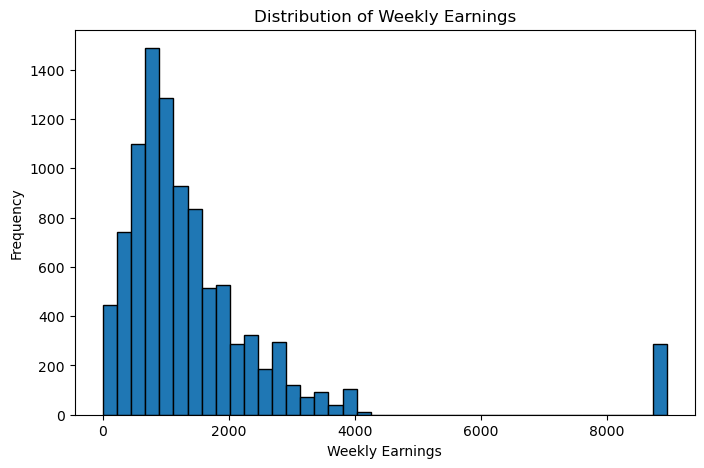

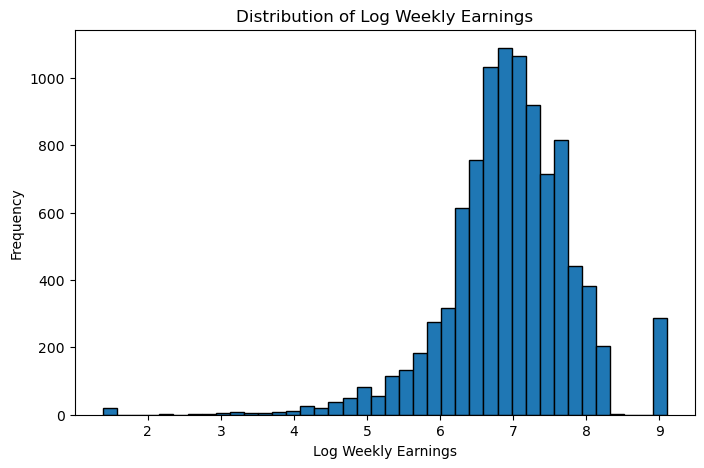

<Figure size 800x500 with 0 Axes>

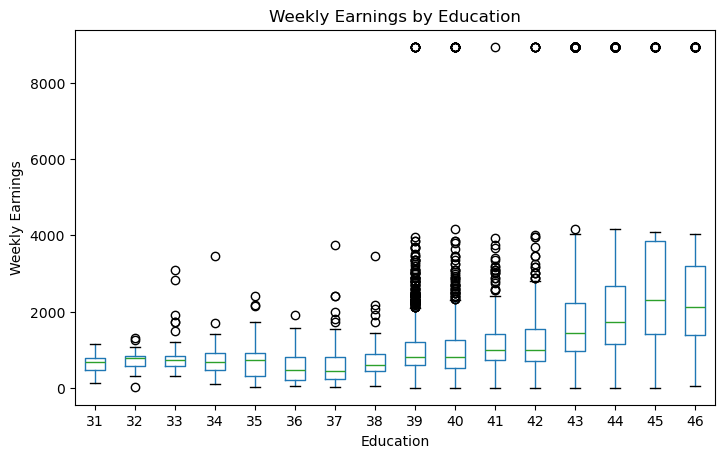

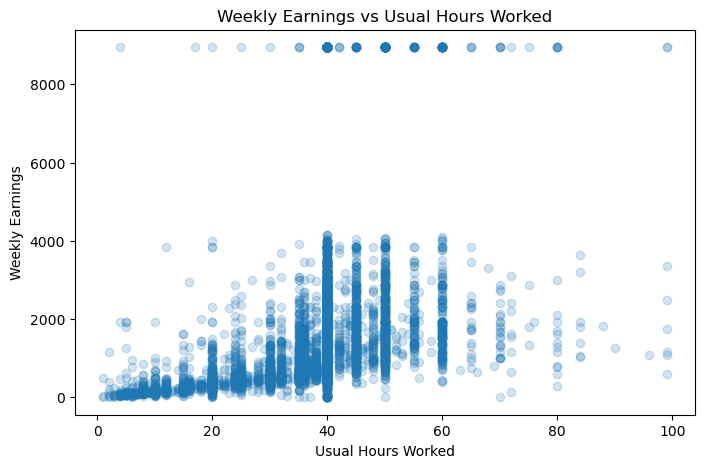

In [34]:
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (8, 5)


plt.figure()
plt.hist(df["weekly_earnings"], bins=40, edgecolor="black")
plt.title("Distribution of Weekly Earnings")
plt.xlabel("Weekly Earnings")
plt.ylabel("Frequency")
plt.show()


plt.figure()
plt.hist(df["log_earnings"], bins=40, edgecolor="black")
plt.title("Distribution of Log Weekly Earnings")
plt.xlabel("Log Weekly Earnings")
plt.ylabel("Frequency")
plt.show()


plt.figure()
df.boxplot(column="weekly_earnings", by="PEEDUCA", grid=False)
plt.title("Weekly Earnings by Education")
plt.suptitle("")
plt.xlabel("Education")
plt.ylabel("Weekly Earnings")
plt.show()


plt.figure()
plt.scatter(df["PEHRUSL1"], df["weekly_earnings"], alpha=0.2)
plt.title("Weekly Earnings vs Usual Hours Worked")
plt.xlabel("Usual Hours Worked")
plt.ylabel("Weekly Earnings")
plt.show()

## Methodology

The analysis will utilize Random Forest Regression model in assessing the strength of prediction of weekly earnings by education and hours worked over demographic variables using CPS December 2024. It is a good choice since it will be able to capture any non-linear relationship and interactions between the variables without having an equation that is too rigid to fit the data.

Log weekly earnings will be used as a dependent variable to reduce the skewness of the distribution, hence, increasing its suitability in predicting earnings. Independent variables will be: age, education, usual hours worked, sex, marital status, race, and citizenship status.

The data preparation involved limiting our sample observations to those having positive weekly earnings, and then retaining the variables we need for our analysis. Then cleaning our data on weekly earnings, finally taking the logarithm of the earnings variable.

In order to measure the accuracy of our model, I will perform cross validation. This involves dividing our data into five folds where we train our model on four of them, leaving out the last one to use it for testing our model. I will then repeat this procedure five times so that all our folds have been left out for testing purposes. The accuracy of this model will be assessed using the Root Mean Squared Error (RMSE). Therefore, the lower the RMSE, the better the model.

I did a small grid search on the hyperparameters including tree numbers, maximum depth, min samples required for split, min samples required for leaf node, and max features considered for splitting. I selected the optimal combination of the parameters based on average cross validated RMSE, and then estimated the final Random Forest model using the entire sample data set.

## Random Forest with K Fold Cross Validation

In [29]:
import sklearn.ensemble as en
from sklearn.model_selection import KFold, ParameterGrid
from sklearn.metrics import mean_squared_error

# Define explanatory variables and dependent variable
Xvars = ['PRTAGE', 'PEEDUCA', 'PEHRUSL1', 'PESEX', 'PEMARITL', 'PTDTRACE', 'PRCITSHP']
yvar = 'log_earnings'

# Use the cleaned dataset
X = df[Xvars]
y = df[yvar]

# Set up parameter grid
param_grid = {
    'n_estimators': [50, 100, 200],
    'max_depth': [5, 10, 15],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'max_features': ['sqrt', 'log2']
}

# Set up 5 fold cross validation
k = 5
kf = KFold(n_splits=k, shuffle=True, random_state=4465)

# Store results
results = []

# Loop over all parameter combinations
for params in ParameterGrid(param_grid):
    
    rmse_list = []
    
    for train_index, test_index in kf.split(X):
        
        X_train = X.iloc[train_index]
        X_test = X.iloc[test_index]
        y_train = y.iloc[train_index]
        y_test = y.iloc[test_index]
        
        rf = en.RandomForestRegressor(
            n_estimators=params['n_estimators'],
            max_depth=params['max_depth'],
            min_samples_split=params['min_samples_split'],
            min_samples_leaf=params['min_samples_leaf'],
            max_features=params['max_features'],
            random_state=4465,
            n_jobs=-1
        )
        
        rf.fit(X_train, y_train)
        y_hat = rf.predict(X_test)
        
        rmse = np.sqrt(mean_squared_error(y_test, y_hat))
        rmse_list.append(rmse)
    
    avg_rmse = np.mean(rmse_list)
    
    results.append({
        'n_estimators': params['n_estimators'],
        'max_depth': params['max_depth'],
        'min_samples_split': params['min_samples_split'],
        'min_samples_leaf': params['min_samples_leaf'],
        'max_features': params['max_features'],
        'avg_rmse': avg_rmse
    })

# Convert results to DataFrame
results_df = pd.DataFrame(results)

# Show best model
best_model = results_df.loc[results_df['avg_rmse'].idxmin()]
print("Best Parameters:")
print(best_model)

Best Parameters:
n_estimators              200
max_depth                  10
min_samples_split          10
min_samples_leaf            1
max_features             sqrt
avg_rmse             0.603162
Name: 62, dtype: object


In [30]:
# Fit final model using best parameters
rf_final = en.RandomForestRegressor(
    n_estimators=int(best_model['n_estimators']),
    max_depth=int(best_model['max_depth']),
    min_samples_split=int(best_model['min_samples_split']),
    min_samples_leaf=int(best_model['min_samples_leaf']),
    max_features=best_model['max_features'],
    random_state=4465,
    n_jobs=-1
)

rf_final.fit(X, y)

# Predict fitted values
y_hat_final = rf_final.predict(X)

# RMSE on full sample
final_rmse = np.sqrt(mean_squared_error(y, y_hat_final))
print("Final RMSE:", final_rmse)

Final RMSE: 0.5619234019117384


In [31]:
# Variable importance
importance = pd.DataFrame({
    'Variable': Xvars,
    'Importance': rf_final.feature_importances_
})

importance = importance.sort_values(by='Importance', ascending=False)
importance

,Variable,Importance
2,PEHRUSL1,0.522309
1,PEEDUCA,0.222356
0,PRTAGE,0.140684
4,PEMARITL,0.047920
3,PESEX,0.037971
5,PTDTRACE,0.014450
6,PRCITSHP,0.014311


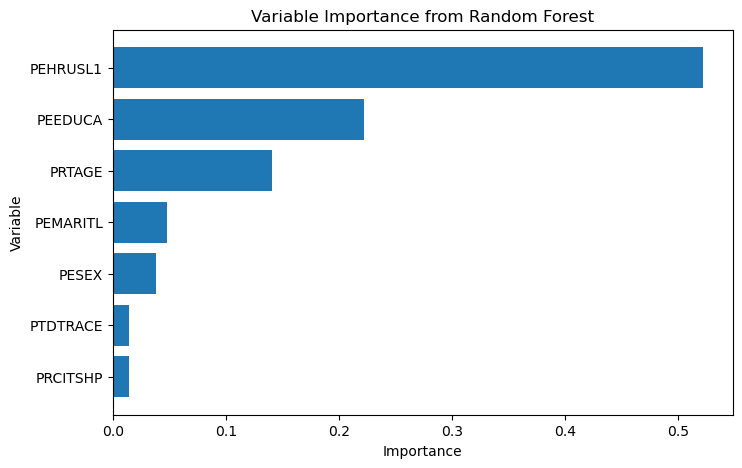

In [32]:
plt.figure(figsize=(8,5))
plt.barh(importance['Variable'], importance['Importance'])
plt.gca().invert_yaxis()
plt.title('Variable Importance from Random Forest')
plt.xlabel('Importance')
plt.ylabel('Variable')
plt.show()

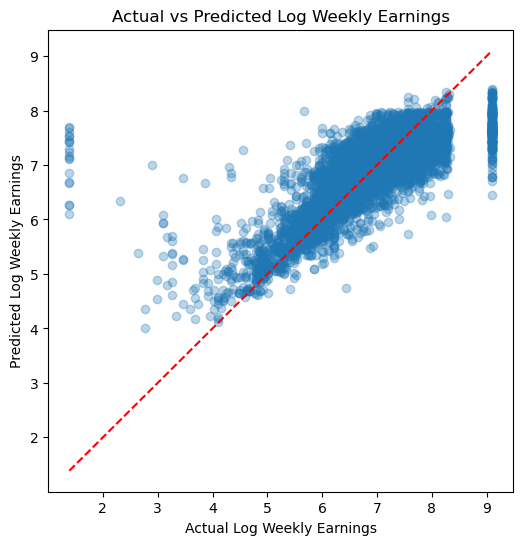

In [33]:
plt.figure(figsize=(6,6))
plt.scatter(y, y_hat_final, alpha=0.3)
plt.plot([y.min(), y.max()], [y.min(), y.max()], 'r--')
plt.title('Actual vs Predicted Log Weekly Earnings')
plt.xlabel('Actual Log Weekly Earnings')
plt.ylabel('Predicted Log Weekly Earnings')
plt.show()

## Results
From the random forest model with five-fold cross validation, the optimum parameters include 200 trees, maximum depth of 10, minimum samples split of 10, minimum samples leaf of 1, and maximum features of square root of total predictors. Based on these values, the cross validation mean RMSE is approximately 0.603. After using all the predictor variables, the final model with all folds fitted together yielded an RMSE value of about 0.562, indicating good performance in predicting the response.

Based on the variable importance plot, the usual hours worked predictor variable emerges as the most important predictor for weekly earnings with an importance measure of about 0.522. Education comes next with an importance measure of about 0.222. The next predictor in terms of importance is age with importance of about 0.141. On the other hand, demographic variables such as marital status, sex, race, and citizenship status have very low importance scores. They range from a minimum of less than 0.05 for citizenship status to 0.06 for marital status.

From these results, we can conclude that in the prediction of weekly earnings in the CPS December 2024 data, education and hours worked are clear dominators compared to the other demographic variables. Age still has a meaningful importance score. The variable importance graph below provides even more evidence that age, education, and hours worked have much higher importance scores than all other predictors.

A scatter plot of actual and predicted log weekly earnings confirms a strong positive relationship in the predictor-response relationship. Most observations lie close to the 45-degree reference line. This means that predictions are relatively near actual values. Nonetheless, dispersion still occurs especially in the lowest and highest levels of earning.

## Conclusion
This project examined the extent to which education and hours worked dominate demographic variables in predicting weekly earnings using CPS December 2024 data. After cleaning the data and estimating a Random Forest model with 5 fold cross validation, the results show that usual hours worked and education are by far the most important predictors of weekly earnings. Age also plays a role, but the demographic variables included in the model, such as sex, race, marital status, and citizenship status, contribute much less to prediction.

Overall, the evidence suggests that labor market factors connected to human capital and work effort are much stronger predictors of weekly earnings than basic demographic characteristics in this sample. While demographic variables may still matter indirectly or through broader structural channels, their direct predictive contribution in this model is limited. Therefore, the research question can be answered by saying that education and hours worked strongly dominate demographic variables in predicting weekly earnings in CPS December 2024.

## Final Remarks
Based on my analysis, it appears that education and typical number of hours worked are the best determinants of weekly earnings, while the demographic variables employed in the model play only an insignificant part in their determination. From the findings of the analysis that variables associated with labor supply and human capital have a bigger impact on predicting earnings compared to those associated with personal attributes.

While there are variables that the model does not account for, it clearly shows that the demographic variables in question are dominated by education and typical number of hours worked.